In [1]:
import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam
from keras.losses import CategoricalCrossentropy
from keras.metrics import AUC
from keras.utils import to_categorical
import matplotlib.pyplot as plt
import random
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix
from tensorflow.keras.metrics import Accuracy

import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPooling2D


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
## plot 9 images as gray scale
############################################################################
def plot_and_save_images(images, filename):
    plt.figure()
    plt.suptitle('10 images of the MNIST categories', fontsize=14, fontweight='bold')
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i], cmap=plt.get_cmap('gray'))
        plt.axis('off')
    plt.tight_layout()
    plt.savefig(filename)  # Save the plot as an image
    plt.show()

##############################################################################
##plot confusion matrix heatmap
def conf_mat_plot(confusion_matrix, filename): #not really nessecary
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='d')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.savefig(filename)  # Save the plot as a PNG image
    plt.show()

# Example usage
#conf_mat_plot(confusion_matrix, 'confusion_matrix.png')

##############################################################################
# function to Plot the performance

def plot_performance(history, filename):
    plt.figure(figsize=(14, 6))
    metric_1 = list(history.history.keys())[0]
    metric_2 = list(history.history.keys())[2]
    plt.plot(history.history[metric_1])
    plt.plot(history.history[metric_2])
    plt.title('Loss error function')
    plt.ylabel(metric_1)
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.savefig(filename)  # Save the plot as a .png file
    plt.show()

##############################################################################

def create_and_compile_dnn(input_shape, num_classes):
    ffnet = keras.models.Sequential()
    ffnet.add(keras.Input(shape=input_shape))
    ffnet.add(keras.layers.Dense(600, activation='relu'))
    ffnet.add(keras.layers.Dropout(0.5))
    ffnet.add(keras.layers.Dense(128, activation='relu'))
    ffnet.add(keras.layers.Dropout(0.25))
    ffnet.add(keras.layers.Flatten())
    ffnet.add(keras.layers.Dense(num_classes, activation='softmax'))
    ffnet.compile(optimizer='adam', loss=keras.losses.CategoricalCrossentropy(), metrics=[AUC(), 'accuracy'])
    ffnet.summary()
    return ffnet

##############################################################################

def create_and_compile_cnn(input_shape, num_classes):
    my_cnn = Sequential()
    my_cnn.add(Input(shape=input_shape))
    my_cnn.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
    my_cnn.add(MaxPooling2D(pool_size=(2, 2)))
    my_cnn.add(Conv2D(20, kernel_size=(3, 3), activation='relu'))
    my_cnn.add(Dropout(0.5))
    my_cnn.add(MaxPooling2D(pool_size=(2, 2)))
    my_cnn.add(Dropout(0.3))
    my_cnn.add(Flatten())  # Flatten the output
    my_cnn.add(Dense(num_classes, activation='softmax'))
    my_cnn.summary()
    my_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', AUC()])
    return my_cnn


##############################################################################

def plot_metrics(histories):
    for i, history in enumerate(histories):
        # Plot AUC curves
        plt.figure()
        plt.plot(history.history['auc'], label=f'Train Fold {i+1}')
        plt.plot(history.history['val_auc'], label=f'Validation Fold {i+1}')
        plt.title(f'Model AUC curve - Fold {i+1}')
        plt.xlabel('Epoch')
        plt.ylabel('AUC')
        plt.legend(['Train', 'Validation'])
        plt.savefig(f'auc_plot_fold_{i+1}.png')

        # Plot loss curves
        plt.figure()
        plt.plot(history.history['loss'], label=f'Train Fold {i+1}')
        plt.plot(history.history['val_loss'], label=f'Validation Fold {i+1}')
        plt.title(f'Model Loss - Fold {i+1}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend(['Train', 'Validation'])
        plt.savefig(f'loss_plot_fold_{i+1}.png')



In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data() #split MNIST data in train,test set

11490434/11490434 [==============================] - 0s 0us/step


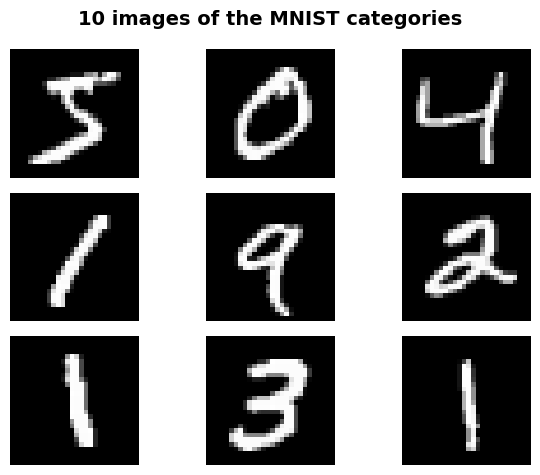

Input data(train) shape is : (60000, 28, 28)
Input data(test) shape is : (10000, 28, 28)
Output data(train) shape is : (60000,)
Output data(test) shape is : (10000,)
Train set has the following classes [0 1 2 3 4 5 6 7 8 9]
Test set has the following classes [0 1 2 3 4 5 6 7 8 9]


In [5]:
# show the plot
plot_and_save_images(x_train, 'grid_images_initial.png')
plt.pause(4)
num_classes=(np.unique(y_train)).shape[0]
print("Input data(train) shape is :", x_train.shape)
print("Input data(test) shape is :", x_test.shape)
print("Output data(train) shape is :", y_train.shape)
print("Output data(test) shape is :", y_test.shape)
print("Train set has the following classes", np.unique(y_train) )
print("Test set has the following classes", np.unique(y_test) )

In [6]:
input_shape = (28, 28,)
num_classes = np.unique(y_train).shape[0]
dnn = create_and_compile_dnn(input_shape, num_classes)

# Define the number of folds and other variables
num_folds = 6
results_dnn = []
histories = []

# Create the K-Fold cross-validator
kf = StratifiedKFold(n_splits=num_folds, shuffle=True)

# Perform the cross-validation
fold = 1
for train_index, val_index in kf.split(x_train, y_train):
    print('K-fold  #', fold)
    # Get the training and validation data for the current fold
    X_train_fold, X_val_fold = x_train[train_index], x_train[val_index]
    y_train_fold, y_val_fold = y_train[train_index], y_train[val_index]

    # Train the model
    early_stopping = keras.callbacks.EarlyStopping(monitor='loss', patience=2)

    # Train the model and save the history
    history = dnn.fit(
        X_train_fold.reshape(-1, 28, 28),
        to_categorical(y_train_fold),
        validation_data=(X_val_fold.reshape(-1, 28, 28), to_categorical(y_val_fold)),
        epochs=50,
        batch_size=50,
        callbacks=[early_stopping]  # Add the EarlyStopping callback
    )

    # Save the history for the current fold
    histories.append(history)

    # Evaluate the model on the training set
    y_train_pred = dnn.predict(X_train_fold.reshape(-1, 28, 28))
    y_train_pred = np.argmax(y_train_pred, axis=1)
    train_accuracy = accuracy_score(y_train_fold, y_train_pred)
    train_precision = precision_score(y_train_fold, y_train_pred, average='macro')
    train_recall = recall_score(y_train_fold, y_train_pred, average='macro')
    train_f1 = f1_score(y_train_fold, y_train_pred, average='macro')

    # Evaluate the model on the test set
    y_test_pred = dnn.predict(x_test.reshape(-1, 28, 28))
    y_test_pred = np.argmax(y_test_pred, axis=1)
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_precision = precision_score(y_test, y_test_pred, average='macro')
    test_recall = recall_score(y_test, y_test_pred, average='macro')
    test_f1 = f1_score(y_test, y_test_pred, average='macro')

    # Record the results in the dataframe
    results_dnn.append(['DNN', 'Train', fold, train_accuracy, train_precision, train_recall, train_f1])
    results_dnn.append(['DNN', 'Test', fold, test_accuracy, test_precision, test_recall, test_f1])

    fold += 1


# Create the dataframe
columns = ['Technique', 'Set', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
df = pd.DataFrame(results_dnn, columns=columns)


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 28, 600)           17400     
                                                                 
 dropout (Dropout)           (None, 28, 600)           0         
                                                                 
 dense_1 (Dense)             (None, 28, 128)           76928     
                                                                 
 dropout_1 (Dropout)         (None, 28, 128)           0         
                                                                 
 flatten (Flatten)           (None, 3584)              0         
                                                                 
 dense_2 (Dense)             (None, 10)                35850     
                                                                 
Total params: 130,178
Trainable params: 130,178
Non-trai

In [7]:
# Saving the trained model
model_name = 'MNIST_DNN.h5'
dnn.save(model_name)

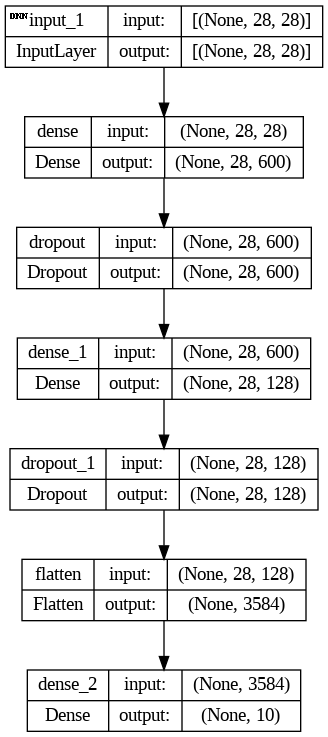

In [8]:

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import plot_model
from PIL import Image, ImageDraw, ImageFont

model = load_model('MNIST_DNN.h5')


#model = load_model('dnn_model.h5')

# Visualize the model architecture and save the image
plot_model(model, to_file='model.png', show_shapes=True)

# Open the image
image = Image.open('model.png')

# Add a title to the image using PIL
draw = ImageDraw.Draw(image)

title = 'DNN'
draw.text((10, 10), title, fill='black')

# Save the image with the title
image.show()
image.save('model_with_title.png')


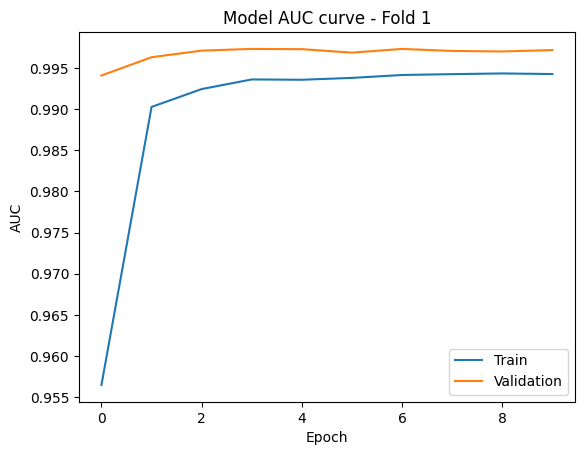

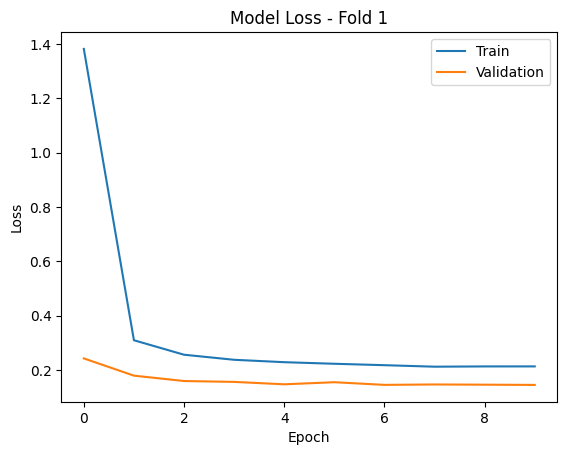

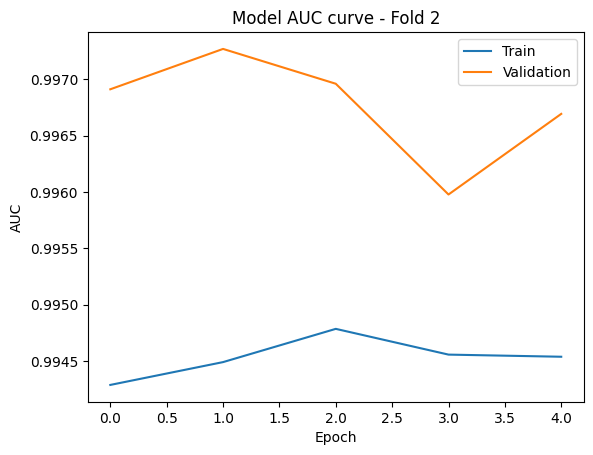

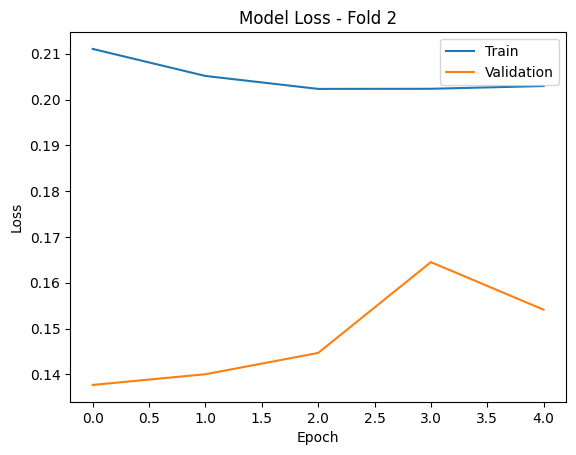

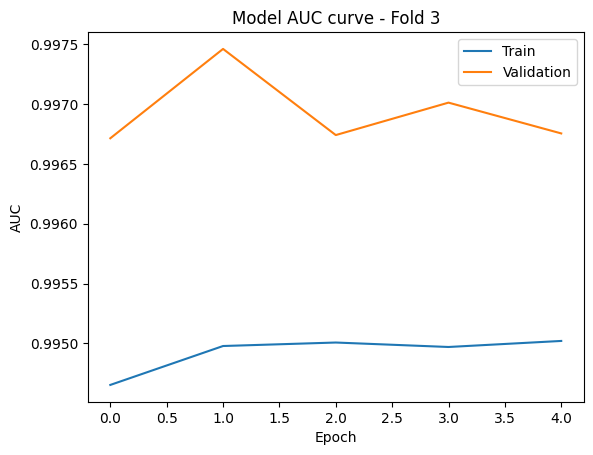

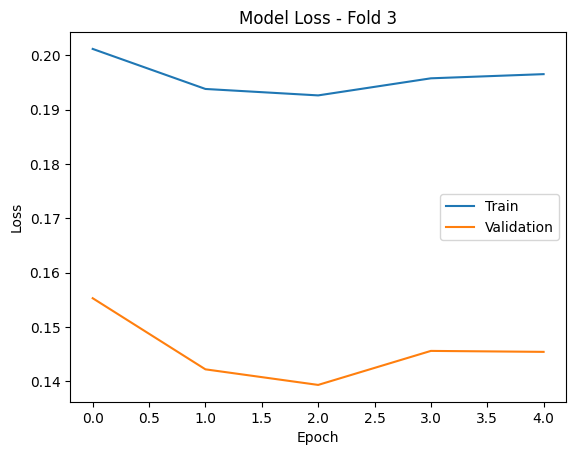

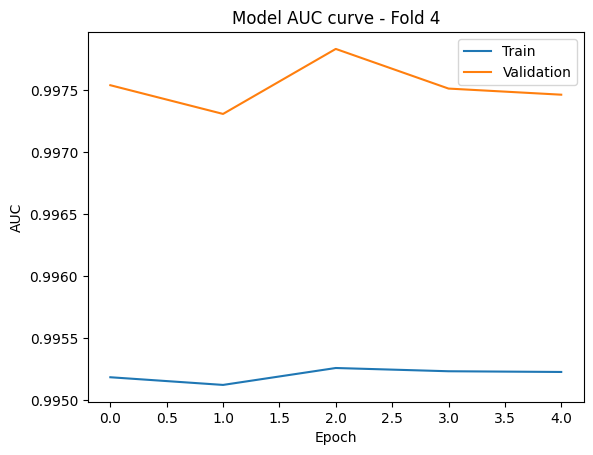

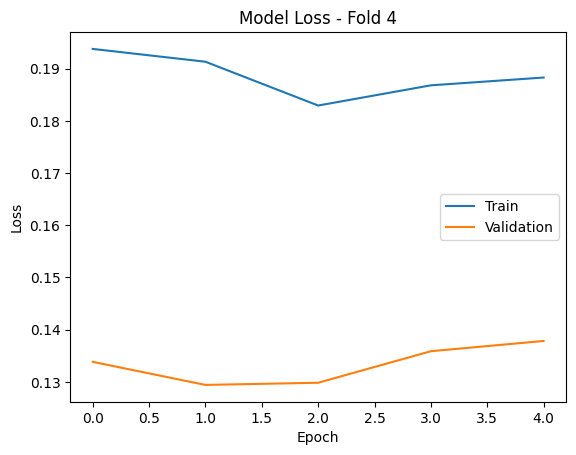

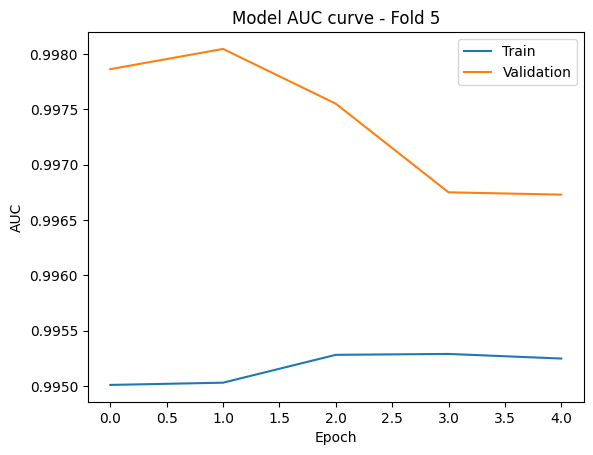

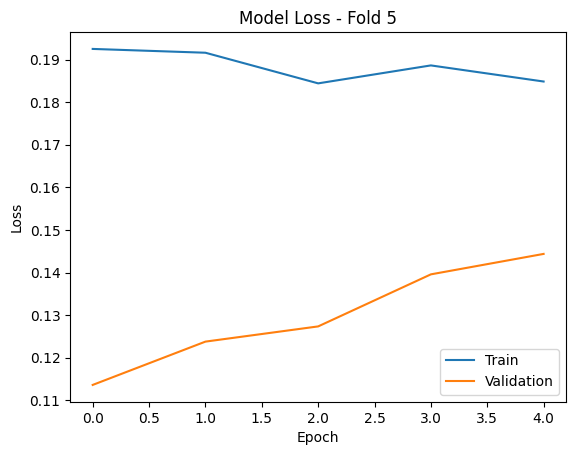

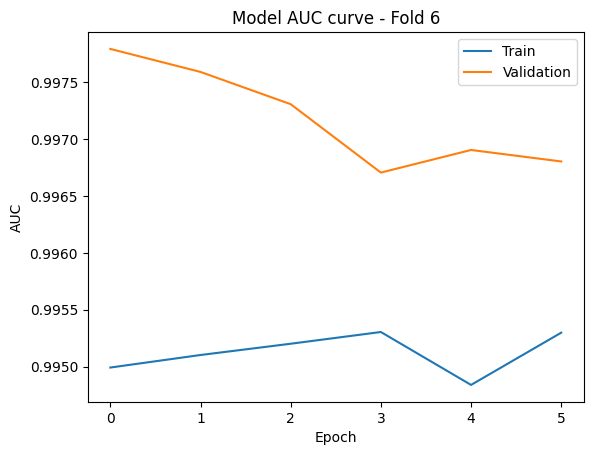

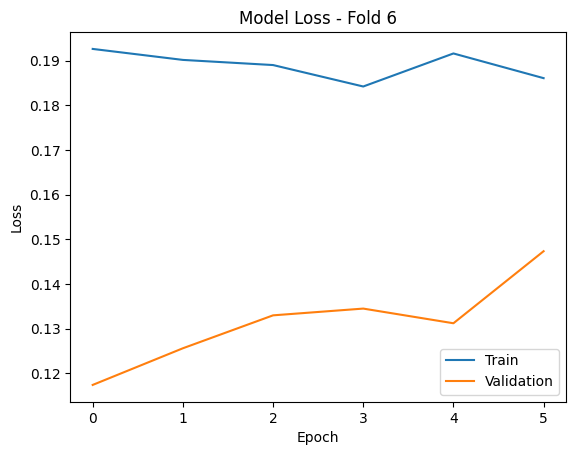

In [9]:

# Save the dataframe as a CSV file
file_path = '/content/drive/MyDrive/Colab Notebooks/erotima1.csv'

#file_path = '/content/drive/MyDrive/Colab Notebooks/deep Learning/erotima1.csv'
df.to_csv(file_path, index=False)

df.to_csv('erotima1.csv', index=False)

# Call the plot_metrics function
plot_metrics(histories)



In [10]:
best_f1_score = 0
best_model_index = -1

# Iterate over the dataframe
for index, row in df.iterrows():
    if row['Set'] == 'Test':
        fold = row['Fold']
        f1_score = row['F1 Score']

        # Compare the F1 score to find the best model
        if f1_score > best_f1_score:
            best_f1_score = f1_score
            best_model_index = fold

# Print the best model's fold and F1 score
print("Best Model - Fold:", best_model_index)
print("Best F1 Score:", best_f1_score)

df

Best Model - Fold: 4
Best F1 Score: 0.9576699463656249


,Technique,Set,Fold,Accuracy,Precision,Recall,F1 Score
0,DNN,Train,1,0.95782,0.958650,0.957365,0.957728
1,DNN,Test,1,0.95120,0.952179,0.950701,0.951055
2,DNN,Train,2,0.96214,0.962082,0.961820,0.961705
3,DNN,Test,2,0.95610,0.956119,0.955679,0.955580
4,DNN,Train,3,0.96372,0.964284,0.963020,0.963445
5,DNN,Test,3,0.95630,0.957285,0.955362,0.955863
6,DNN,Train,4,0.96716,0.967083,0.966986,0.966988
7,DNN,Test,4,0.95790,0.957903,0.957613,0.957670
8,DNN,Train,5,0.96278,0.963086,0.962529,0.962700
9,DNN,Test,5,0.95520,0.955709,0.954784,0.955029


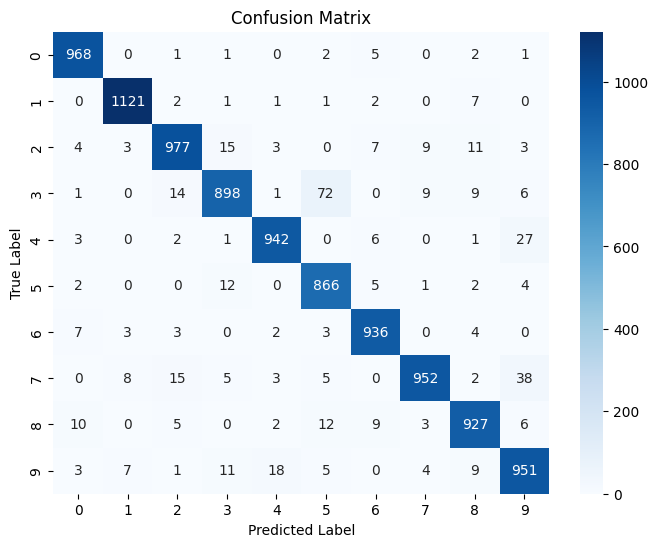

In [11]:

confusion_matrix = confusion_matrix(y_test, y_test_pred)
conf_mat_plot(confusion_matrix, 'confusion_matrix.png')

In [12]:

# Clear all variables except 'df' and 'histories'
keep_variables = {'df', 'histories', 'results_dnn','results_dnn','histories_cnn','df2','best_model_index' }


import keras
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.optimizers import Adam
from keras.losses import CategoricalCrossentropy
from keras.metrics import AUC
from keras.utils import to_categorical
import matplotlib.pyplot as plt
import random
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow.keras.layers import Conv2D, MaxPooling2D


In [13]:
## plot 9 images as gray scale
############################################################################
def plot_and_save_images(images, filename):
    plt.figure()
    plt.suptitle('10 images of the MNIST categories', fontsize=14, fontweight='bold')
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(images[i], cmap=plt.get_cmap('gray'))
        plt.axis('off')
    plt.tight_layout()
    plt.savefig(filename)  # Save the plot as an image
    plt.show()

##############################################################################
##plot confusion matrix heatmap
def conf_mat_plot(confusion_matrix, filename): #not really nessecary
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix, annot=True, cmap='Blues', fmt='d')
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.savefig(filename)  # Save the plot as a PNG image
    plt.show()

# Example usage
#conf_mat_plot(confusion_matrix, 'confusion_matrix.png')

##############################################################################
# function to Plot the performance

def plot_performance(history, filename):
    plt.figure(figsize=(14, 6))
    metric_1 = list(history.history.keys())[0]
    metric_2 = list(history.history.keys())[2]
    plt.plot(history.history[metric_1])
    plt.plot(history.history[metric_2])
    plt.title('Loss error function')
    plt.ylabel(metric_1)
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.savefig(filename)  # Save the plot as a .png file
    plt.show()

##############################################################################

def create_and_compile_dnn(input_shape, num_classes):
    ffnet = keras.models.Sequential()
    ffnet.add(keras.Input(shape=input_shape))
    ffnet.add(keras.layers.Dense(600, activation='relu'))
    ffnet.add(keras.layers.Dropout(0.5))
    ffnet.add(keras.layers.Dense(128, activation='relu'))
    ffnet.add(keras.layers.Dropout(0.25))
    ffnet.add(keras.layers.Flatten())
    ffnet.add(keras.layers.Dense(num_classes, activation='softmax'))
    ffnet.compile(optimizer='adam', loss=keras.losses.CategoricalCrossentropy(), metrics=[AUC()])
    ffnet.summary()
    return ffnet

##############################################################################

def create_and_compile_cnn(input_shape, num_classes):
    my_cnn = Sequential()
    my_cnn.add(Input(shape=input_shape))
    my_cnn.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
    my_cnn.add(MaxPooling2D(pool_size=(2, 2)))
    my_cnn.add(Conv2D(20, kernel_size=(3, 3), activation='relu'))
    my_cnn.add(Dropout(0.5))
    my_cnn.add(MaxPooling2D(pool_size=(2, 2)))
    my_cnn.add(Dropout(0.3))
    my_cnn.add(Flatten())  # Flatten the output
    my_cnn.add(Dense(num_classes, activation='softmax'))
    my_cnn.summary()
    my_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC()])
    return my_cnn


##############################################################################
def plot_metrics_cnn(histories):
    for i, history in enumerate(histories):
        # Plot AUC curves
        plt.figure()
        plt.plot(history.history['auc_1'], label=f'Train Fold {i+1}')
        plt.plot(history.history['val_auc_1'], label=f'Validation Fold {i+1}')
        plt.title(f'Model AUC curve - Fold {i+1}')
        plt.xlabel('Epoch')
        plt.ylabel('AUC')
        plt.legend(['Train', 'Validation'])
        plt.savefig(f'auc_plot_fold_{i+1}.png')

        # Plot loss curves
        plt.figure()
        plt.plot(history.history['loss'], label=f'Train Fold {i+1}')
        plt.plot(history.history['val_loss'], label=f'Validation Fold {i+1}')
        plt.title(f'Model Loss - Fold {i+1}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend(['Train', 'Validation'])
        plt.savefig(f'loss_plot_fold_{i+1}.png')



In [14]:
(x_train, y_train), (x_test, y_test) = mnist.load_data() #split MNIST data in train,test set
input_shape = (28,28,1)
num_classes = np.unique(y_train).shape[0]
my_cnn = create_and_compile_cnn(input_shape, num_classes)
# Define the number of folds and other variables
num_folds = 6
results_cnn = []
histories_cnn = []


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 64)        640       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 64)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 20)        11540     
                                                                 
 dropout_2 (Dropout)         (None, 11, 11, 20)        0         
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 20)         0         
 2D)                                                             
                                                                 
 dropout_3 (Dropout)         (None, 5, 5, 20)         

In [15]:



histories_cnn = []
results_cnn = []

# Create the K-Fold cross-validator
kf = StratifiedKFold(n_splits=num_folds, shuffle=True)

# Perform the cross-validation
fold = 1
for train_index, val_index in kf.split(x_train, y_train):
    print('K-fold  #', fold)
    # Get the training and validation data for the current fold
    X_train_fold_cnn, X_val_fold_cnn = x_train[train_index], x_train[val_index]
    y_train_fold_cnn, y_val_fold_cnn = y_train[train_index], y_train[val_index]



    # Train the model
    early_stopping = keras.callbacks.EarlyStopping(monitor='loss', patience=2)
    # Train the model and save the history
    # ...

# Train the model and save the history
    history = my_cnn.fit(
        X_train_fold_cnn.reshape(-1, 28, 28, 1),
        to_categorical(y_train_fold_cnn, num_classes=10),
        validation_data=(X_val_fold_cnn.reshape(-1, 28, 28, 1), to_categorical(y_val_fold_cnn, num_classes=10)),
        epochs=50,
        batch_size=50,
        callbacks=[early_stopping]
    )

    # Save the history for the current fold
    histories_cnn.append(history)

    # Evaluate the model on the training set
    y_train_pred_cnn = my_cnn.predict(X_train_fold_cnn.reshape(-1, 28, 28, 1))
    y_train_pred_cnn = np.argmax(y_train_pred_cnn, axis=1)
    train_accuracy_cnn = accuracy_score(y_train_fold_cnn, y_train_pred_cnn)
    train_precision_cnn = precision_score(y_train_fold_cnn, y_train_pred_cnn, average='macro')
    train_recall_cnn = recall_score(y_train_fold_cnn, y_train_pred_cnn, average='macro')

    # Evaluate the model on the test set
    y_test_pred_cnn = my_cnn.predict(x_test.reshape(-1, 28, 28, 1))
    y_test_pred_cnn = np.argmax(y_test_pred_cnn, axis=1)
    test_accuracy_cnn = accuracy_score(y_test, y_test_pred_cnn)
    test_precision_cnn = precision_score(y_test, y_test_pred_cnn, average='macro')
    test_recall_cnn = recall_score(y_test, y_test_pred_cnn, average='macro')

    # Compute the F1 score separately
    train_f1_cnn = f1_score(y_train_fold_cnn, y_train_pred_cnn, average='macro')
    test_f1_cnn = f1_score(y_test, y_test_pred_cnn, average='macro')

    # Record the results in the dataframe
    results_cnn.append(['CNN', 'Train', fold, train_accuracy_cnn, train_precision_cnn, train_recall_cnn, train_f1_cnn])
    results_cnn.append(['CNN', 'Test', fold, test_accuracy_cnn, test_precision_cnn, test_recall_cnn, test_f1_cnn])


    fold += 1

# Create the dataframe
columns = ['Technique', 'Set', 'Fold', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
df2 = pd.DataFrame(results_cnn, columns=columns)
df = pd.concat([df, df2])

# Save the dataframe as a CSV file
df.to_csv('erotima1.csv', index=False)



K-fold  # 1
Epoch 1/50
1000/1000 [==============================] - 12s 5ms/step - loss: 1.3755 - accuracy: 0.6535 - auc_1: 0.9283 - val_loss: 0.2601 - val_accuracy: 0.9340 - val_auc_1: 0.9955
Epoch 2/50
1000/1000 [==============================] - 5s 5ms/step - loss: 0.4063 - accuracy: 0.8763 - auc_1: 0.9870 - val_loss: 0.1438 - val_accuracy: 0.9605 - val_auc_1: 0.9980
Epoch 3/50
1000/1000 [==============================] - 5s 5ms/step - loss: 0.2667 - accuracy: 0.9191 - auc_1: 0.9929 - val_loss: 0.1110 - val_accuracy: 0.9704 - val_auc_1: 0.9986
Epoch 4/50
1000/1000 [==============================] - 5s 5ms/step - loss: 0.2093 - accuracy: 0.9358 - auc_1: 0.9948 - val_loss: 0.0937 - val_accuracy: 0.9756 - val_auc_1: 0.9990
Epoch 5/50
1000/1000 [==============================] - 5s 5ms/step - loss: 0.1735 - accuracy: 0.9466 - auc_1: 0.9961 - val_loss: 0.0781 - val_accuracy: 0.9794 - val_auc_1: 0.9991
Epoch 6/50
1000/1000 [==============================] - 5s 5ms/step - loss: 0.1559 - ac

,Technique,Set,Fold,Accuracy,Precision,Recall,F1 Score
0,DNN,Train,1,0.95782,0.958650,0.957365,0.957728
1,DNN,Test,1,0.95120,0.952179,0.950701,0.951055
2,DNN,Train,2,0.96214,0.962082,0.961820,0.961705
3,DNN,Test,2,0.95610,0.956119,0.955679,0.955580
4,DNN,Train,3,0.96372,0.964284,0.963020,0.963445
5,DNN,Test,3,0.95630,0.957285,0.955362,0.955863
6,DNN,Train,4,0.96716,0.967083,0.966986,0.966988
7,DNN,Test,4,0.95790,0.957903,0.957613,0.957670
8,DNN,Train,5,0.96278,0.963086,0.962529,0.962700
9,DNN,Test,5,0.95520,0.955709,0.954784,0.955029


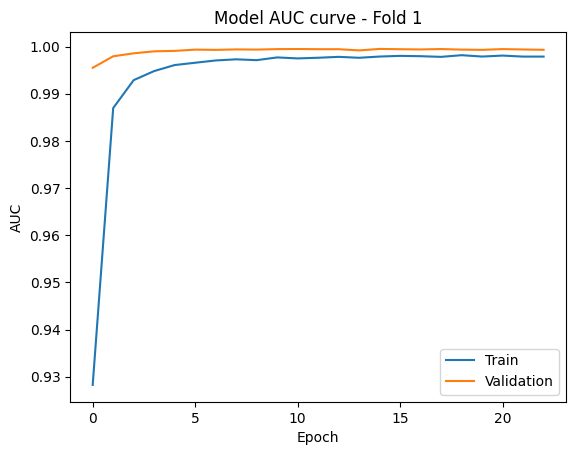

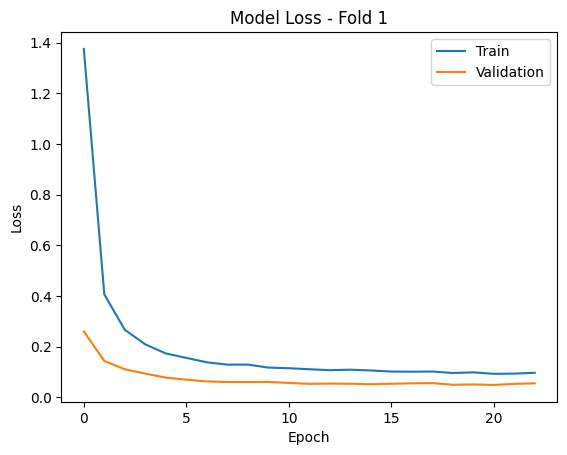

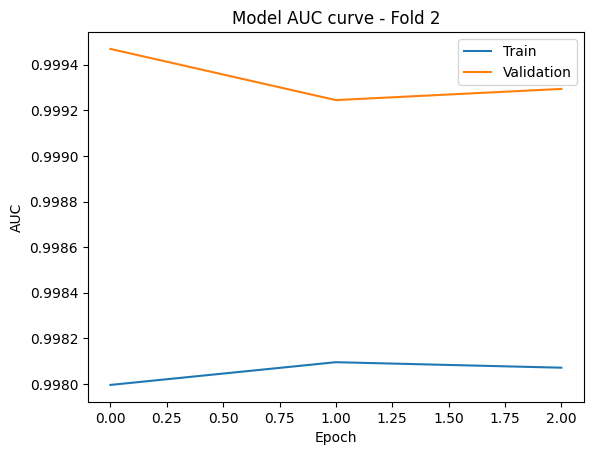

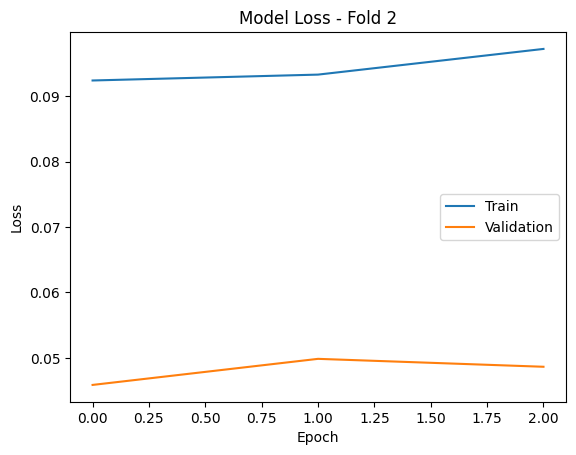

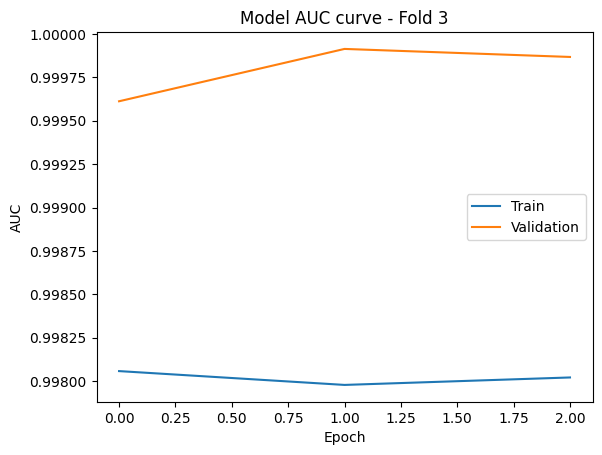

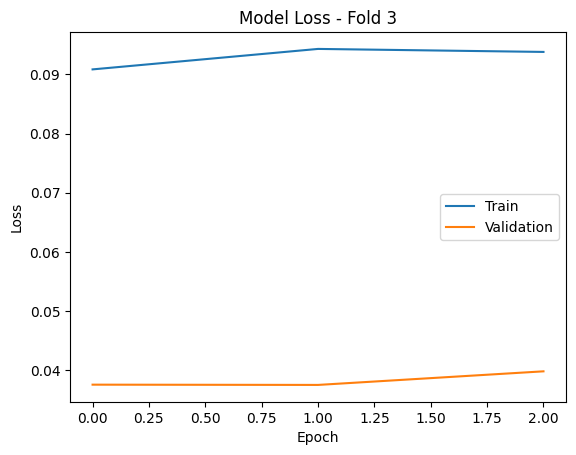

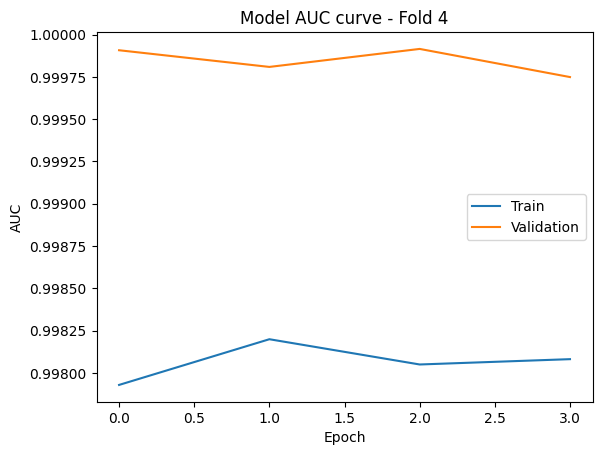

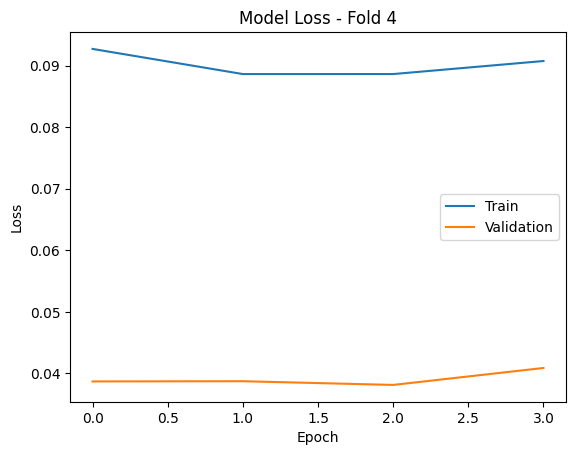

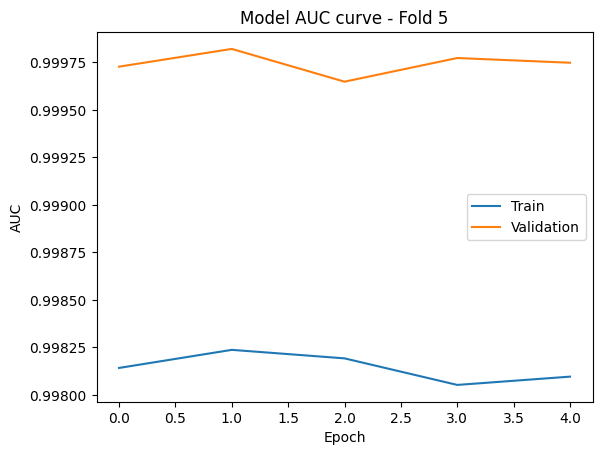

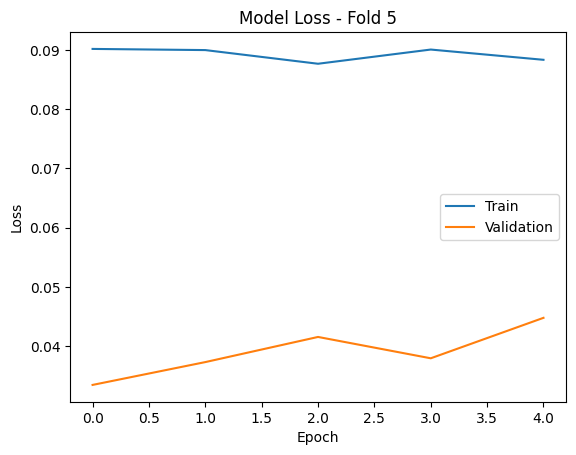

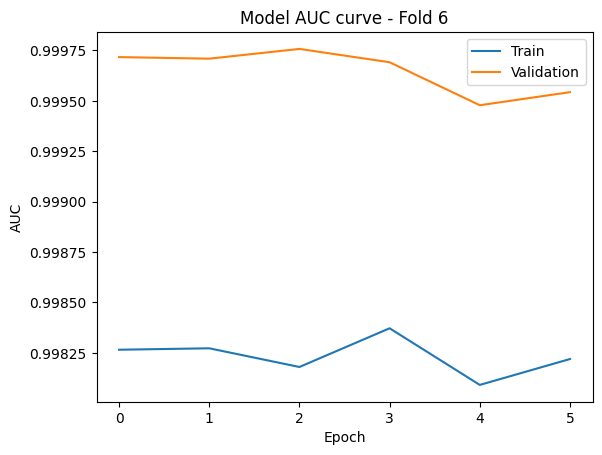

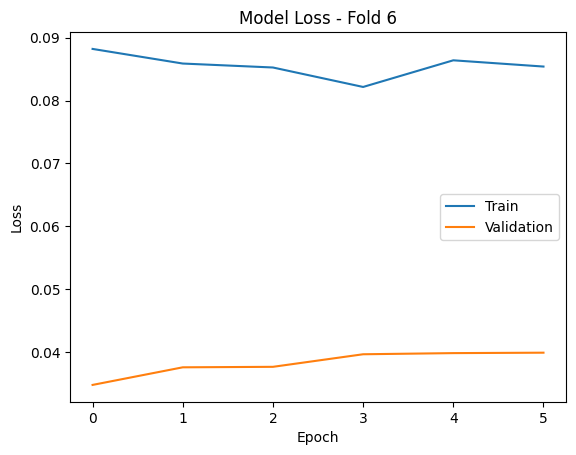

In [16]:
# Call the plot_metrics function
plot_metrics_cnn(histories_cnn)
df

In [17]:
# Save the dataframe as a CSV file
df2.to_csv('erotima1_cnn.csv', index=False)


In [18]:
best_f1_score_cnn = 0
best_model_index_cnn = -1

# Iterate over the dataframe
for index, row in df2.iterrows():
    if row['Set'] == 'Test':
        fold = row['Fold']
        f1_score = row['F1 Score']

        # Compare the F1 score to find the best model
        if f1_score > best_f1_score_cnn:
            best_f1_score_cnn= f1_score
            best_model_index_cnn = fold

# Print the best model's fold and F1 score
print("Best Model - Fold:", best_model_index_cnn)
print("Best F1 Score:", best_f1_score_cnn)

df

Best Model - Fold: 3
Best F1 Score: 0.9881262970490139


,Technique,Set,Fold,Accuracy,Precision,Recall,F1 Score
0,DNN,Train,1,0.95782,0.958650,0.957365,0.957728
1,DNN,Test,1,0.95120,0.952179,0.950701,0.951055
2,DNN,Train,2,0.96214,0.962082,0.961820,0.961705
3,DNN,Test,2,0.95610,0.956119,0.955679,0.955580
4,DNN,Train,3,0.96372,0.964284,0.963020,0.963445
5,DNN,Test,3,0.95630,0.957285,0.955362,0.955863
6,DNN,Train,4,0.96716,0.967083,0.966986,0.966988
7,DNN,Test,4,0.95790,0.957903,0.957613,0.957670
8,DNN,Train,5,0.96278,0.963086,0.962529,0.962700
9,DNN,Test,5,0.95520,0.955709,0.954784,0.955029


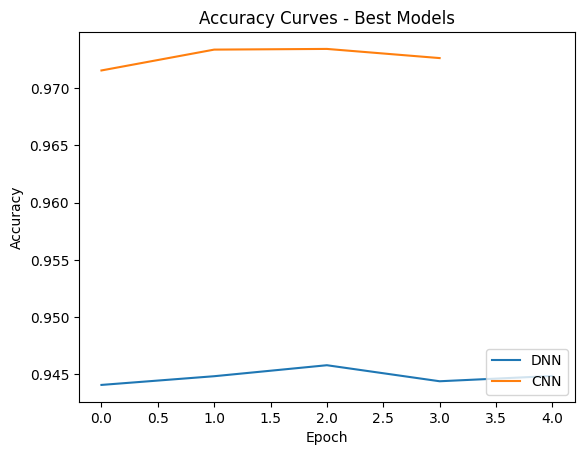

<Figure size 640x480 with 0 Axes>

In [19]:
# Retrieve accuracy data for the best model
accuracy_data_dnn = histories[best_model_index].history['accuracy']
accuracy_data_cnn = histories_cnn[best_model_index_cnn].history['accuracy']

# Plot the accuracy curves
plt.plot(accuracy_data_dnn, label='DNN')
plt.plot(accuracy_data_cnn, label='CNN')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curves - Best Models')
plt.legend(loc='lower right')
 # Add legend in the lower right corner
plt.show()
plt.savefig('accuracy_best_plots.png')

In [20]:
best_f1_score_cnn

0.9881262970490139

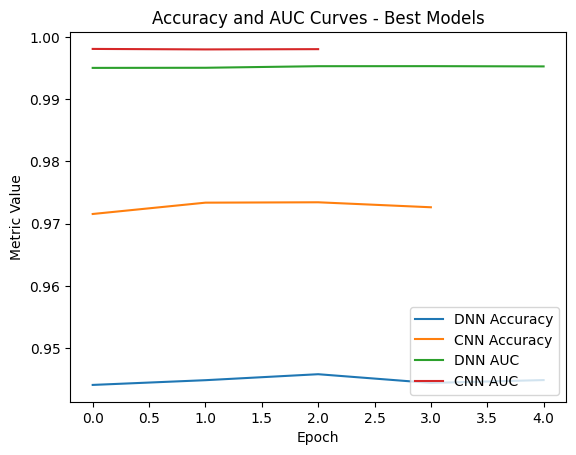

In [21]:
# Retrieve accuracy data for the best models
accuracy_data_dnn = histories[best_model_index].history['accuracy']
accuracy_data_cnn = histories_cnn[best_model_index_cnn].history['accuracy']

# Retrieve AUC data for the best models
auc_data_dnn = histories[best_model_index].history['auc']
auc_data_cnn = histories_cnn[best_model_index_cnn-1].history['auc_1']

# Plot the accuracy curves
plt.plot(accuracy_data_dnn, label='DNN Accuracy')
plt.plot(accuracy_data_cnn, label='CNN Accuracy')

# Plot the AUC curves
plt.plot(auc_data_dnn, label='DNN AUC')
plt.plot(auc_data_cnn, label='CNN AUC')

plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.title('Accuracy and AUC Curves - Best Models')
plt.legend(loc='lower right')  # Add legend in the lower right corner
plt.show()

from keras.models import save_model

# Αποθήκευση DNN
save_model(dnn, 'dnn_model.h5')

# Αποθήκευση CNN
save_model(my_cnn, 'cnn_model.h5')


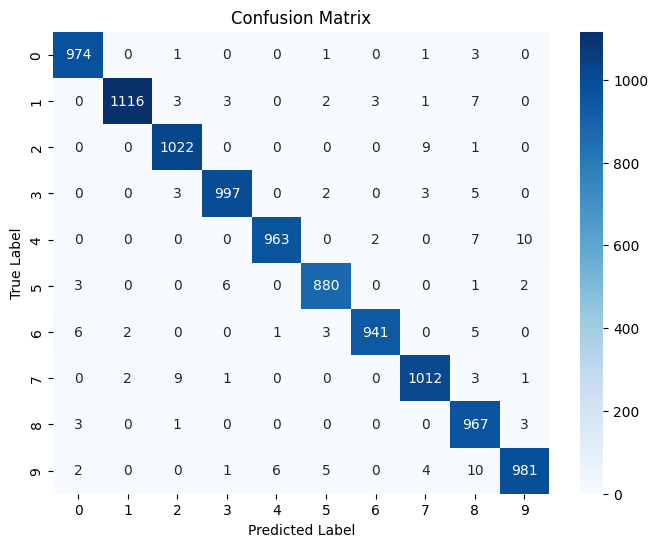

In [23]:

confusion_matrix = confusion_matrix(y_test, y_test_pred_cnn)
conf_mat_plot(confusion_matrix, 'confusion_matrix.png')

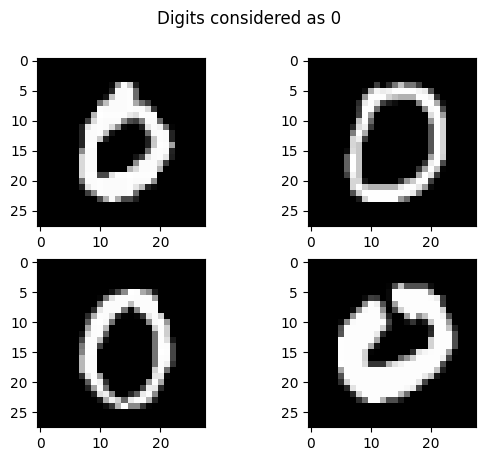

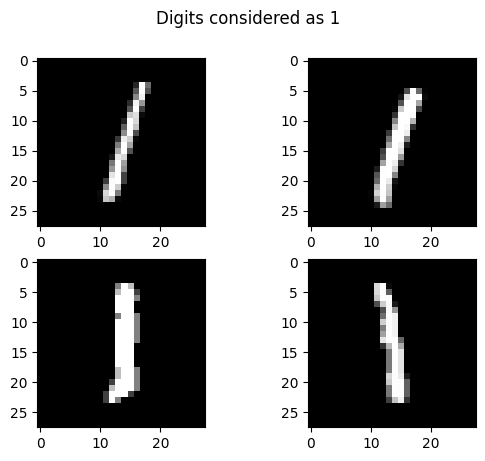

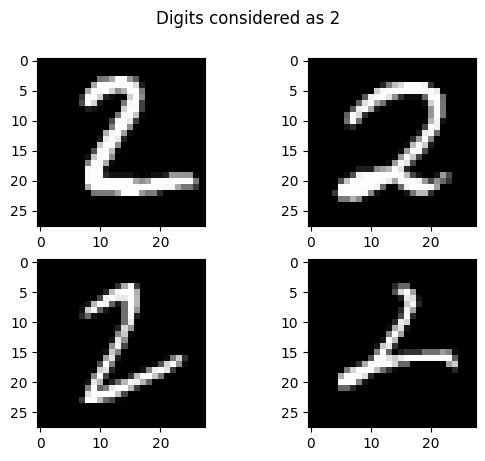

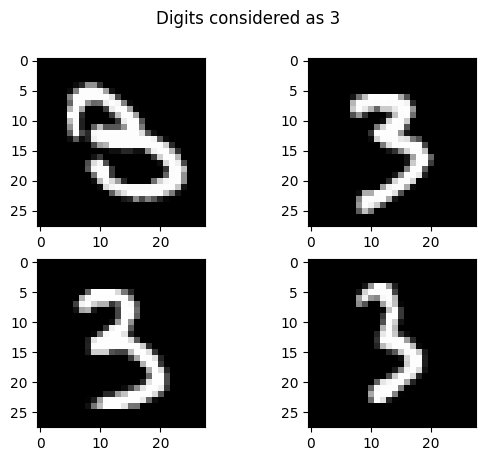

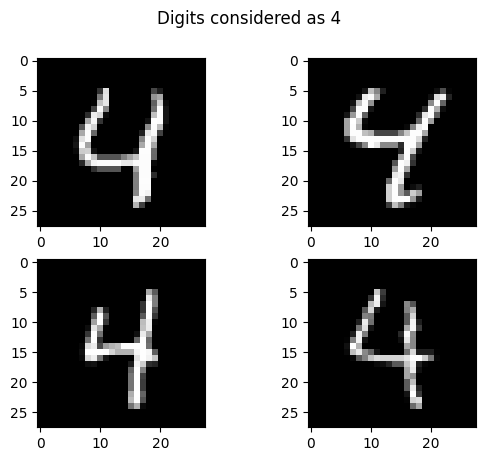

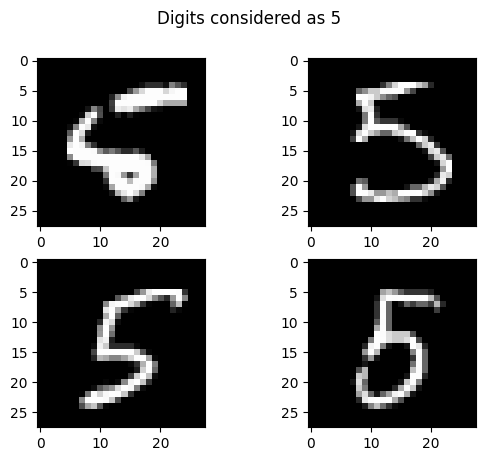

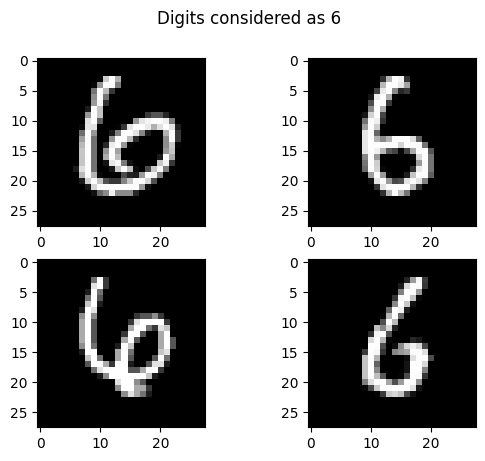

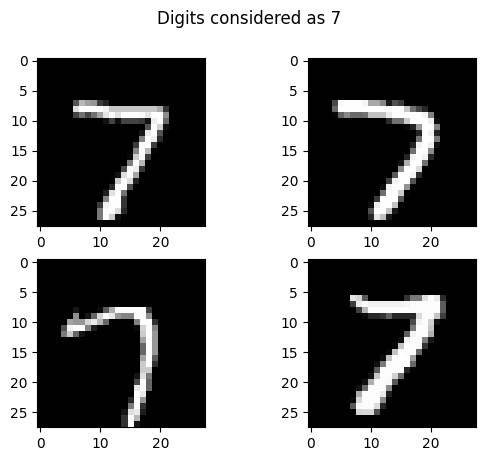

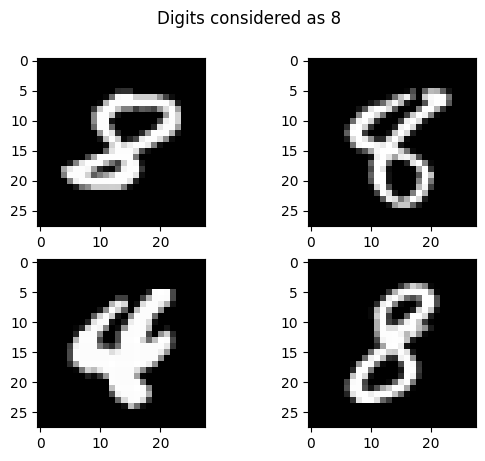

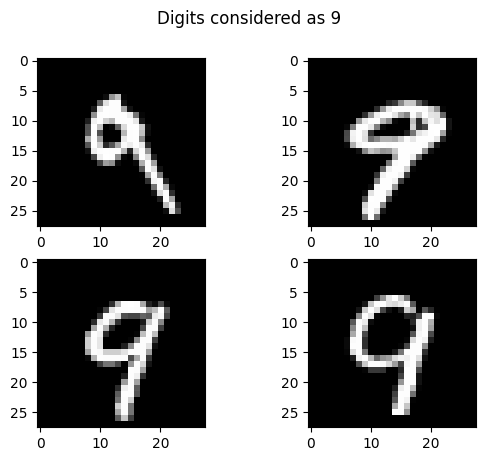

In [24]:
class_to_demonstrate = 0
while sum(y_test_pred_cnn == class_to_demonstrate) > 4:
    tmp_idxs_to_use = np.where(y_test_pred_cnn == class_to_demonstrate)[0]

    # create new plot window
    plt.figure()

    # plot 4 images as gray scale
    plt.subplot(221)
    plt.imshow(x_test[tmp_idxs_to_use[0]], cmap=plt.get_cmap('gray'))
    plt.subplot(222)
    plt.imshow(x_test[tmp_idxs_to_use[1]], cmap=plt.get_cmap('gray'))
    plt.subplot(223)
    plt.imshow(x_test[tmp_idxs_to_use[2]], cmap=plt.get_cmap('gray'))
    plt.subplot(224)
    plt.imshow(x_test[tmp_idxs_to_use[3]], cmap=plt.get_cmap('gray'))
    tmp_title = 'Digits considered as ' + str(class_to_demonstrate)
    plt.suptitle(tmp_title)

    # show the plot
    plt.show()
    plt.pause(2)

    # update the class to demonstrate index
    class_to_demonstrate += 1


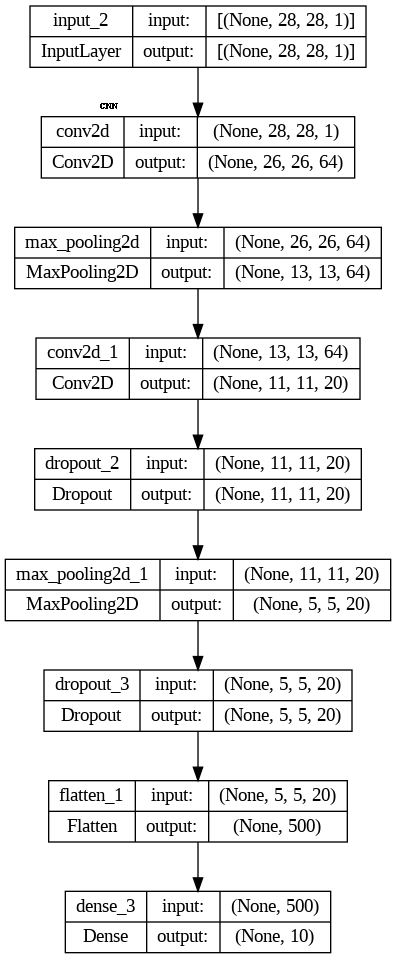

In [25]:

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import plot_model
from PIL import Image, ImageDraw, ImageFont

model = load_model('cnn_model.h5')


#model = load_model('dnn_model.h5')

# Visualize the model architecture and save the image
plot_model(model, to_file='model.png', show_shapes=True)

# Open the image
image = Image.open('model.png')

# Add a title to the image using PIL
draw = ImageDraw.Draw(image)

title = 'CNN'
draw.text((100, 100), title, fill='black')

# Save the image with the title
image.show()
image.save('model_with_title.png')
